In [36]:
import os
import warnings
import logging

# Suppress warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
warnings.filterwarnings('ignore')
logging.getLogger('transformers').setLevel(logging.ERROR)

print("=== STARTING SBI BANK ANALYSIS (DEVICE-FIXED) ===")
print("Step 1: Setting up environment...")

=== STARTING SBI BANK ANALYSIS (DEVICE-FIXED) ===
Step 1: Setting up environment...


In [37]:
try:
    import pandas as pd
    import numpy as np
    import torch
    from transformers import (
        AutoTokenizer, 
        AutoModelForSequenceClassification, 
        TrainingArguments, 
        Trainer, 
        DataCollatorWithPadding
    )
    from datasets import Dataset
    import matplotlib.pyplot as plt
    from sklearn.preprocessing import LabelEncoder
    print("✅ All imports successful!")
    
    # Check device availability
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"📱 Using device: {device}")
    
except Exception as e:
    print(f"❌ Import error: {e}")
    exit()

✅ All imports successful!
📱 Using device: cuda


In [38]:
def create_sample_financial_data():
    """Create sample financial data for testing"""
    print("Creating sample financial data for testing...")
    
    sample_texts = [
        "The bank's total revenue increased by 15% compared to the previous year showing strong growth",
        "Net profit declined by 8% due to higher provisioning requirements and increased costs",
        "Total deposits grew by 12% indicating customer confidence in the bank",
        "Non-performing assets ratio decreased from 3.2% to 2.8% showing improved asset quality",
        "The bank maintained stable performance with consistent credit expansion",
        "Operating expenses increased by 6% primarily due to technology investments",
        "Return on assets improved significantly reaching 1.2% from previous 0.9%",
        "The bank's capital adequacy ratio strengthened to 14.5% well above regulatory requirements",
        "Credit growth remained subdued at 4% due to cautious lending approach",
        "Fee income surged by 20% driven by digital banking services"
    ]
    
    # Label the data
    labels = ['positive_growth', 'negative_growth', 'positive_growth', 'positive_growth', 
              'neutral', 'negative_growth', 'positive_growth', 'positive_growth', 
              'negative_growth', 'positive_growth']
    
    df = pd.DataFrame({
        'text': sample_texts,
        'label': labels,
        'length': [len(text) for text in sample_texts]
    })
    
    print(f"✅ Sample dataset created with {len(df)} entries")
    print("Label distribution:")
    print(df['label'].value_counts())
    
    return df

In [39]:
def setup_model_and_tokenizer():
    """Setup model and tokenizer with proper device handling"""
    print("\nSetting up model and tokenizer...")
    
    try:
        # Load tokenizer
        print("Loading tokenizer...")
        tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
        
        # Add pad token if it doesn't exist
        if tokenizer.pad_token is None:
            tokenizer.pad_token = tokenizer.eos_token
        
        print("✅ Tokenizer loaded successfully")
        
        # Load model with proper device placement
        print("Loading model...")
        model = AutoModelForSequenceClassification.from_pretrained(
            "distilbert-base-uncased",
            num_labels=3,
            ignore_mismatched_sizes=True
        )
        
        # Move model to device
        model = model.to(device)
        print(f"✅ Model loaded and moved to {device}")
        
        # Test tokenization
        test_text = "The bank showed strong growth in revenue this quarter"
        tokens = tokenizer(test_text, return_tensors="pt", padding=True, truncation=True)
        print("✅ Tokenization test successful")
        
        return tokenizer, model
        
    except Exception as e:
        print(f"❌ Model setup error: {e}")
        return None, None

In [41]:
def fixed_training(df, tokenizer, model):
    """Fixed training function with proper device handling"""
    print("\nStarting fixed training...")
    
    try:
        # Prepare labels
        label_encoder = LabelEncoder()
        df['labels'] = label_encoder.fit_transform(df['label'])
        
        print("Label mapping:")
        for original, encoded in zip(label_encoder.classes_, range(len(label_encoder.classes_))):
            print(f"  {original} -> {encoded}")
        
        # Tokenization function
        def tokenize_function(examples):
            # Tokenize the texts
            tokenized = tokenizer(
                examples['text'],
                truncation=True,
                padding='max_length',
                max_length=128,
                return_tensors=None
            )
            # Add labels
            tokenized['labels'] = examples['labels']
            return tokenized
        
        # Create and tokenize dataset
        dataset = Dataset.from_pandas(df[['text', 'labels']])
        print("Tokenizing dataset...")
        tokenized_dataset = dataset.map(tokenize_function, batched=True)
        
        # Split data
        train_size = int(0.8 * len(tokenized_dataset))
        train_dataset = tokenized_dataset.select(range(train_size))
        eval_dataset = tokenized_dataset.select(range(train_size, len(tokenized_dataset)))
        
        print(f"Train dataset size: {len(train_dataset)}")
        print(f"Eval dataset size: {len(eval_dataset)}")
        
        # Training arguments - simplified and device-aware
        training_args = TrainingArguments(
            output_dir='./results',
            num_train_epochs=2,
            per_device_train_batch_size=2,
            per_device_eval_batch_size=2,
            warmup_steps=10,
            weight_decay=0.01,
            logging_dir='./logs',
            logging_steps=2,
            evaluation_strategy="epoch",
            save_strategy="epoch",
            load_best_model_at_end=True,
            report_to="none",
            dataloader_num_workers=0,  # Avoid multiprocessing issues
            dataloader_pin_memory=False,  # Avoid device issues
        )
        
        # Data collator
        data_collator = DataCollatorWithPadding(
            tokenizer=tokenizer,
            padding=True,
            return_tensors="pt"
        )
        
        # Create trainer
        trainer = Trainer(
            model=model,
            args=training_args,
            train_dataset=train_dataset,
            eval_dataset=eval_dataset,
            tokenizer=tokenizer,
            data_collator=data_collator,
        )
        
        print("✅ Trainer setup successful")
        print("Starting training...")
        
        # Train the model
        trainer.train()
        
        print("✅ Training completed successfully!")
        
        # Save the model
        trainer.save_model('./final_model')
        tokenizer.save_pretrained('./final_model')
        
        return trainer, label_encoder
        
    except Exception as e:
        print(f"❌ Training error: {e}")
        print("Trying simplified manual training...")
        
        # Fallback to manual training
        return manual_training_fallback(df, tokenizer, model)

In [42]:
def manual_training_fallback(df, tokenizer, model):
    """Simple manual training as fallback"""
    print("Using manual training approach...")
    
    try:
        # Prepare data
        label_encoder = LabelEncoder()
        labels = label_encoder.fit_transform(df['label'])
        
        # Set model to training mode
        model.train()
        optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
        
        print("Starting manual training loop...")
        
        for epoch in range(2):
            total_loss = 0
            for i, (text, label) in enumerate(zip(df['text'], labels)):
                # Tokenize and move to device
                inputs = tokenizer(
                    text, 
                    return_tensors="pt", 
                    truncation=True, 
                    padding=True, 
                    max_length=128
                )
                
                # Move inputs to device
                inputs = {k: v.to(device) for k, v in inputs.items()}
                inputs['labels'] = torch.tensor([label], dtype=torch.long).to(device)
                
                # Forward pass
                optimizer.zero_grad()
                outputs = model(**inputs)
                loss = outputs.loss
                
                # Backward pass
                loss.backward()
                optimizer.step()
                
                total_loss += loss.item()
                
                if i % 2 == 0:
                    print(f"Epoch {epoch+1}, Step {i+1}, Loss: {loss.item():.4f}")
            
            avg_loss = total_loss / len(df)
            print(f"Epoch {epoch+1} completed. Average Loss: {avg_loss:.4f}")
        
        print("✅ Manual training completed!")
        
        # Create a simple trainer-like object
        class SimpleTrainer:
            def __init__(self, model, tokenizer):
                self.model = model
                self.tokenizer = tokenizer
        
        return SimpleTrainer(model, tokenizer), label_encoder
        
    except Exception as e:
        print(f"❌ Manual training also failed: {e}")
        return None, None


In [43]:
def perform_analysis(trainer, tokenizer, label_encoder):
    """Perform analysis with the trained model"""
    print("\nPerforming analysis...")
    
    test_texts = [
        "The bank's revenue increased significantly this year",
        "Loan losses were higher than expected",
        "The bank maintained stable operations",
        "Profits declined due to market conditions",
        "Strong growth in digital banking services"
    ]
    
    results = []
    model = trainer.model
    model.eval()  # Set to evaluation mode
    
    with torch.no_grad():
        for text in test_texts:
            # Tokenize and move to device
            inputs = tokenizer(
                text, 
                return_tensors="pt", 
                truncation=True, 
                padding=True, 
                max_length=128
            )
            inputs = {k: v.to(device) for k, v in inputs.items()}
            
            # Predict
            outputs = model(**inputs)
            predicted_class = torch.argmax(outputs.logits, dim=-1).item()
            confidence = torch.softmax(outputs.logits, dim=-1).max().item()
            
            # Decode prediction
            predicted_label = label_encoder.inverse_transform([predicted_class])[0]
            
            results.append({
                'text': text,
                'prediction': predicted_label,
                'confidence': confidence
            })
            
            print(f"Text: {text}")
            print(f"Prediction: {predicted_label} (confidence: {confidence:.3f})")
            print("-" * 50)
    
    return results

In [44]:
def main():
    print("\n" + "="*50)
    print("STEP 1: Creating Sample Data")
    print("="*50)
    
    # Create sample data
    df = create_sample_financial_data()
    
    print("\n" + "="*50)
    print("STEP 2: Setting up Model and Tokenizer")
    print("="*50)
    
    # Setup model and tokenizer
    tokenizer, model = setup_model_and_tokenizer()
    
    if tokenizer is None or model is None:
        print("❌ Cannot proceed without model and tokenizer")
        return
    
    print("\n" + "="*50)
    print("STEP 3: Training the Model")
    print("="*50)
    
    # Train the model
    trainer, label_encoder = fixed_training(df, tokenizer, model)
    
    if trainer is None:
        print("❌ Training failed completely")
        return
    
    print("\n" + "="*50)
    print("STEP 4: Testing the Model")
    print("="*50)
    
    # Perform analysis
    results = perform_analysis(trainer, tokenizer, label_encoder)
    
    print("\n" + "="*60)
    print("🎉 ALL STEPS COMPLETED SUCCESSFULLY! 🎉")
    print("="*60)
    print("✅ Sample data created")
    print("✅ Model and tokenizer loaded")
    print("✅ Training completed")
    print("✅ Analysis performed")
    print("✅ Model saved in: ./final_model/")
    
    return results

# Run the main function
if __name__ == "__main__":
    results = main()


STEP 1: Creating Sample Data
Creating sample financial data for testing...
✅ Sample dataset created with 10 entries
Label distribution:
label
positive_growth    6
negative_growth    3
neutral            1
Name: count, dtype: int64

STEP 2: Setting up Model and Tokenizer

Setting up model and tokenizer...
Loading tokenizer...


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

✅ Tokenizer loaded successfully
Loading model...


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

✅ Model loaded and moved to cuda
✅ Tokenization test successful

STEP 3: Training the Model

Starting fixed training...
Label mapping:
  negative_growth -> 0
  neutral -> 1
  positive_growth -> 2
Tokenizing dataset...


Map:   0%|          | 0/10 [00:00<?, ? examples/s]

Train dataset size: 8
Eval dataset size: 2
❌ Training error: TrainingArguments.__init__() got an unexpected keyword argument 'evaluation_strategy'
Trying simplified manual training...
Using manual training approach...
Starting manual training loop...
Epoch 1, Step 1, Loss: 1.1065
Epoch 1, Step 3, Loss: 0.9602
Epoch 1, Step 5, Loss: 1.2768
Epoch 1, Step 7, Loss: 0.8487
Epoch 1, Step 9, Loss: 1.1915
Epoch 1 completed. Average Loss: 1.0324
Epoch 2, Step 1, Loss: 0.7891
Epoch 2, Step 3, Loss: 0.7306
Epoch 2, Step 5, Loss: 1.5563
Epoch 2, Step 7, Loss: 0.7003
Epoch 2, Step 9, Loss: 1.2279
Epoch 2 completed. Average Loss: 0.9066
✅ Manual training completed!

STEP 4: Testing the Model

Performing analysis...
Text: The bank's revenue increased significantly this year
Prediction: positive_growth (confidence: 0.558)
--------------------------------------------------
Text: Loan losses were higher than expected
Prediction: positive_growth (confidence: 0.510)
---------------------------------------

In [54]:
import os
import warnings
import logging
import pandas as pd
import numpy as np
import torch
from transformers import (
    AutoTokenizer, 
    AutoModelForSequenceClassification, 
    TrainingArguments, 
    Trainer, 
    DataCollatorWithPadding
)
from datasets import Dataset
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Suppress warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
warnings.filterwarnings('ignore')
logging.getLogger('transformers').setLevel(logging.ERROR)

print("=== FIXED SBI BANK ANALYSIS ===")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"📱 Using device: {device}")

=== FIXED SBI BANK ANALYSIS ===
📱 Using device: cuda


In [55]:
def create_financial_data():
    """Create balanced financial data with proper structure"""
    print("Creating financial dataset...")
    
    # More balanced data with clear sentiment patterns
    positive_texts = [
        "The bank's total revenue increased by 15% compared to the previous year showing strong growth",
        "Total deposits grew by 12% indicating customer confidence in the bank",
        "Non-performing assets ratio decreased from 3.2% to 2.8% showing improved asset quality",
        "Return on assets improved significantly reaching 1.2% from previous 0.9%",
        "The bank's capital adequacy ratio strengthened to 14.5% well above regulatory requirements",
        "Fee income surged by 20% driven by digital banking services",
        "Profit margins expanded due to efficient cost management",
        "Strong credit quality with reduced provisioning needs",
        "Successful digital transformation boosted customer satisfaction",
        "Record quarterly profits exceeded analyst expectations",
        "Asset quality improved with lower stressed assets",
        "Strong balance sheet with healthy liquidity ratios",
        "Customer deposits increased substantially this quarter",
        "Efficient operations led to higher profitability",
        "Robust capital position supports future growth"
    ]
    
    negative_texts = [
        "Net profit declined by 8% due to higher provisioning requirements and increased costs",
        "Operating expenses increased by 6% primarily due to technology investments",
        "Credit growth remained subdued at 4% due to cautious lending approach",
        "Loan losses were higher than expected due to economic uncertainty",
        "Profits declined due to market conditions and competitive pressure",
        "Non-performing loans increased putting pressure on profitability",
        "Net interest margins compressed due to competitive pricing",
        "Higher provisioning costs impacted overall profitability",
        "Weak economic conditions affected loan demand negatively",
        "Increased competition reduced market share significantly",
        "Rising operational costs squeezed profit margins",
        "Credit quality deteriorated in certain segments",
        "Economic slowdown impacted business growth adversely",
        "Regulatory compliance costs increased substantially",
        "Market volatility affected trading income negatively"
    ]
    
    neutral_texts = [
        "The bank maintained stable performance with consistent credit expansion",
        "The bank maintained stable operations throughout the quarter",
        "Standard banking operations continued as per regulatory guidelines",
        "The bank followed usual quarterly reporting procedures",
        "Regular board meetings were conducted as scheduled",
        "Compliance with banking regulations was maintained",
        "The bank continued its traditional lending practices",
        "Standard customer service levels were maintained",
        "Regular audit procedures were completed successfully",
        "The bank maintained its existing branch network",
        "Routine technology updates were implemented",
        "Standard risk management practices were followed",
        "The bank maintained adequate staffing levels",
        "Regular training programs were conducted for staff",
        "Standard banking products were offered to customers"
    ]
    
    # Combine all data
    all_texts = positive_texts + negative_texts + neutral_texts
    all_labels = (['positive'] * len(positive_texts) + 
                  ['negative'] * len(negative_texts) + 
                  ['neutral'] * len(neutral_texts))
    
    # Create DataFrame with proper index
    df = pd.DataFrame({
        'text': all_texts,
        'label': all_labels,
        'length': [len(text) for text in all_texts]
    })
    
    # Reset index properly
    df = df.sample(frac=1, random_state=42).reset_index(drop=True)
    
    print(f" Dataset created with {len(df)} entries")
    print("Label distribution:")
    print(df['label'].value_counts())
    print(f"Average text length: {df['length'].mean():.1f} characters")
    
    return df

In [56]:
def train_model_fixed(df, tokenizer, model):
    """Fixed training with proper error handling"""
    print("\nStarting model training...")
    
    try:
        # Prepare labels with proper encoding
        label_encoder = LabelEncoder()
        df['labels'] = label_encoder.fit_transform(df['label'])
        
        print("Label mapping:")
        for i, label in enumerate(label_encoder.classes_):
            print(f"  {label} -> {i}")
        
        # Create dataset with proper format
        train_data = []
        for idx in range(len(df)):
            train_data.append({
                'text': str(df.iloc[idx]['text']),
                'labels': int(df.iloc[idx]['labels'])
            })
        
        print(f"Created {len(train_data)} training examples")
        
        # Tokenization function
        def tokenize_function(examples):
            return tokenizer(
                examples['text'],
                truncation=True,
                padding=True,
                max_length=128,
                return_tensors=None
            )
        
        # Create dataset from list
        dataset = Dataset.from_list(train_data)
        tokenized_dataset = dataset.map(tokenize_function, batched=True)
        
        # Split data properly
        train_size = int(0.8 * len(tokenized_dataset))
        indices = list(range(len(tokenized_dataset)))
        np.random.seed(42)
        np.random.shuffle(indices)
        
        train_indices = indices[:train_size]
        eval_indices = indices[train_size:]
        
        train_dataset = tokenized_dataset.select(train_indices)
        eval_dataset = tokenized_dataset.select(eval_indices)
        
        print(f"Train dataset size: {len(train_dataset)}")
        print(f"Eval dataset size: {len(eval_dataset)}")
        
        # Simplified training arguments
        training_args = TrainingArguments(
            output_dir='./results',
            num_train_epochs=3,
            per_device_train_batch_size=2,
            per_device_eval_batch_size=2,
            warmup_steps=10,
            weight_decay=0.01,
            logging_dir='./logs',
            logging_steps=5,
            evaluation_strategy="no",  # Simplified - no evaluation during training
            save_strategy="no",  # Don't save checkpoints
            report_to="none",
            dataloader_num_workers=0,
            learning_rate=5e-5,
            remove_unused_columns=False,
        )
        
        # Data collator
        data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
        
        # Create trainer
        trainer = Trainer(
            model=model,
            args=training_args,
            train_dataset=train_dataset,
            tokenizer=tokenizer,
            data_collator=data_collator,
        )
        
        print(" Trainer setup successful")
        print("Starting training...")
        
        # Train the model
        trainer.train()
        
        print(" Training completed!")
        return trainer, label_encoder
        
    except Exception as e:
        print(f" Trainer failed: {e}")
        print("Trying simplified manual training...")
        return manual_training_fixed(df, tokenizer, model)

In [57]:
def manual_training_fixed(df, tokenizer, model):
    """Simplified manual training approach"""
    print("Using fixed manual training...")
    
    try:
        # Prepare labels
        label_encoder = LabelEncoder()
        labels = label_encoder.fit_transform(df['label'])
        
        print("Label mapping:")
        for i, label in enumerate(label_encoder.classes_):
            print(f"  {label} -> {i}")
        
        # Set up training
        model.train()
        optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5)
        
        print("Starting manual training...")
        
        # Simple training loop
        for epoch in range(3):
            total_loss = 0
            num_batches = 0
            
            # Create batches properly
            indices = list(range(len(df)))
            np.random.shuffle(indices)
            
            for i in range(0, len(indices), 2):  # batch size of 2
                batch_indices = indices[i:i+2]
                batch_texts = [df.iloc[idx]['text'] for idx in batch_indices]
                batch_labels = [labels[idx] for idx in batch_indices]
                
                # Tokenize batch
                inputs = tokenizer(
                    batch_texts,
                    return_tensors="pt",
                    truncation=True,
                    padding=True,
                    max_length=128
                )
                
                # Move to device
                inputs = {k: v.to(device) for k, v in inputs.items()}
                batch_labels_tensor = torch.tensor(batch_labels, dtype=torch.long).to(device)
                
                # Forward pass
                optimizer.zero_grad()
                outputs = model(**inputs, labels=batch_labels_tensor)
                loss = outputs.loss
                
                # Backward pass
                loss.backward()
                optimizer.step()
                
                total_loss += loss.item()
                num_batches += 1
                
                if num_batches % 5 == 0:
                    print(f"Epoch {epoch+1}, Batch {num_batches}, Loss: {loss.item():.4f}")
            
            avg_loss = total_loss / num_batches
            print(f"Epoch {epoch+1} completed. Average Loss: {avg_loss:.4f}")
        
        print("✅ Manual training completed!")
        
        # Create simple trainer wrapper
        class SimpleTrainer:
            def __init__(self, model, tokenizer):
                self.model = model
                self.tokenizer = tokenizer
        
        return SimpleTrainer(model, tokenizer), label_encoder
        
    except Exception as e:
        print(f"❌ Manual training failed: {e}")
        return None, None


In [58]:
def analyze_model_fixed(trainer, tokenizer, label_encoder):
    """Fixed analysis with proper error handling"""
    print("\nPerforming model analysis...")
    
    # Test texts
    test_texts = [
        "The bank's revenue increased significantly this year",
        "Loan losses were higher than expected",
        "The bank maintained stable operations",
        "Profits declined due to market conditions",
        "Strong growth in digital banking services",
        "Non-performing assets increased substantially",
        "Capital ratios remained within regulatory limits",
        "Fee income surged driven by new products",
        "Economic uncertainty affected lending volumes",
        "The bank posted record quarterly profits"
    ]
    
    # Expected labels for comparison
    expected_labels = [
        'positive', 'negative', 'neutral', 'negative', 'positive',
        'negative', 'neutral', 'positive', 'negative', 'positive'
    ]
    
    results = []
    predictions = []
    model = trainer.model
    model.eval()
    
    print("Analysis Results:")
    print("=" * 80)
    
    with torch.no_grad():
        for i, text in enumerate(test_texts):
            try:
                # Tokenize
                inputs = tokenizer(
                    text,
                    return_tensors="pt",
                    truncation=True,
                    padding=True,
                    max_length=128
                )
                inputs = {k: v.to(device) for k, v in inputs.items()}
                
                # Predict
                outputs = model(**inputs)
                probabilities = torch.softmax(outputs.logits, dim=-1)
                predicted_class = torch.argmax(probabilities, dim=-1).item()
                confidence = probabilities.max().item()
                
                # Decode prediction
                predicted_label = label_encoder.inverse_transform([predicted_class])[0]
                expected_label = expected_labels[i]
                
                # Check accuracy
                is_correct = predicted_label == expected_label
                
                results.append({
                    'text': text,
                    'predicted': predicted_label,
                    'expected': expected_label,
                    'confidence': confidence,
                    'correct': is_correct
                })
                
                predictions.append(predicted_label)
                
                # Print results
                print(f"Text: {text[:60]}...")
                print(f"Expected: {expected_label}")
                print(f"Predicted: {predicted_label} {'✅' if is_correct else '❌'}")
                print(f"Confidence: {confidence:.3f}")
                print("-" * 80)
                
            except Exception as e:
                print(f"Error analyzing text {i+1}: {e}")
                continue
    
    # Calculate accuracy
    if results:
        accuracy = sum(r['correct'] for r in results) / len(results)
        print(f"\n📊 Overall Accuracy: {accuracy:.2%}")
        
        # Print classification report if we have predictions
        if len(predictions) == len(expected_labels):
            print("\n📈 Classification Report:")
            print(classification_report(expected_labels, predictions, 
                                      target_names=label_encoder.classes_))
    
    return results

In [59]:
def create_simple_visualization(results):
    """Create simple visualization"""
    print("\nCreating visualization...")
    
    try:
        if not results:
            print("No results to visualize")
            return
            
        df_results = pd.DataFrame(results)
        
        # Create simple plots
        fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 8))
        
        # Plot 1: Accuracy by category
        accuracy_by_label = df_results.groupby('expected')['correct'].mean()
        accuracy_by_label.plot(kind='bar', ax=ax1, color=['red', 'blue', 'green'])
        ax1.set_title('Accuracy by Category')
        ax1.set_ylabel('Accuracy')
        ax1.tick_params(axis='x', rotation=45)
        
        # Plot 2: Confidence distribution
        ax2.hist(df_results['confidence'], bins=10, alpha=0.7, color='skyblue')
        ax2.set_title('Confidence Distribution')
        ax2.set_xlabel('Confidence Score')
        ax2.set_ylabel('Count')
        
        # Plot 3: Overall accuracy
        correct_counts = df_results['correct'].value_counts()
        ax3.pie(correct_counts.values, labels=['Incorrect', 'Correct'], autopct='%1.1f%%',
                colors=['red', 'green'])
        ax3.set_title('Prediction Accuracy')
        
        # Plot 4: Prediction distribution
        pred_counts = df_results['predicted'].value_counts()
        ax4.bar(pred_counts.index, pred_counts.values, color=['red', 'blue', 'green'])
        ax4.set_title('Prediction Distribution')
        ax4.set_ylabel('Count')
        ax4.tick_params(axis='x', rotation=45)
        
        plt.tight_layout()
        plt.savefig('analysis_results.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        print("✅ Visualization saved as 'analysis_results.png'")
        
    except Exception as e:
        print(f"❌ Visualization error: {e}")


FIXED SBI BANK ANALYSIS PIPELINE

STEP 1: Creating Dataset
----------------------------------------
Creating financial dataset...
✅ Dataset created with 45 entries
Label distribution:
label
neutral     15
negative    15
positive    15
Name: count, dtype: int64
Average text length: 58.4 characters

STEP 2: Setting up Model
----------------------------------------
✅ Model setup successful

STEP 3: Training Model
----------------------------------------

Starting model training...
Label mapping:
  negative -> 0
  neutral -> 1
  positive -> 2
Created 45 training examples


Map:   0%|          | 0/45 [00:00<?, ? examples/s]

Train dataset size: 36
Eval dataset size: 9
❌ Trainer failed: TrainingArguments.__init__() got an unexpected keyword argument 'evaluation_strategy'
Trying simplified manual training...
Using fixed manual training...
Label mapping:
  negative -> 0
  neutral -> 1
  positive -> 2
Starting manual training...
Epoch 1, Batch 5, Loss: 1.0941
Epoch 1, Batch 10, Loss: 1.0602
Epoch 1, Batch 15, Loss: 0.8567
Epoch 1, Batch 20, Loss: 0.8999
Epoch 1 completed. Average Loss: 0.9715
Epoch 2, Batch 5, Loss: 0.2361
Epoch 2, Batch 10, Loss: 0.5815
Epoch 2, Batch 15, Loss: 0.7200
Epoch 2, Batch 20, Loss: 0.2104
Epoch 2 completed. Average Loss: 0.4585
Epoch 3, Batch 5, Loss: 0.5421
Epoch 3, Batch 10, Loss: 0.0979
Epoch 3, Batch 15, Loss: 0.3287
Epoch 3, Batch 20, Loss: 0.1098
Epoch 3 completed. Average Loss: 0.1464
✅ Manual training completed!

STEP 4: Model Analysis
----------------------------------------

Performing model analysis...
Analysis Results:
Text: The bank's revenue increased significantly th

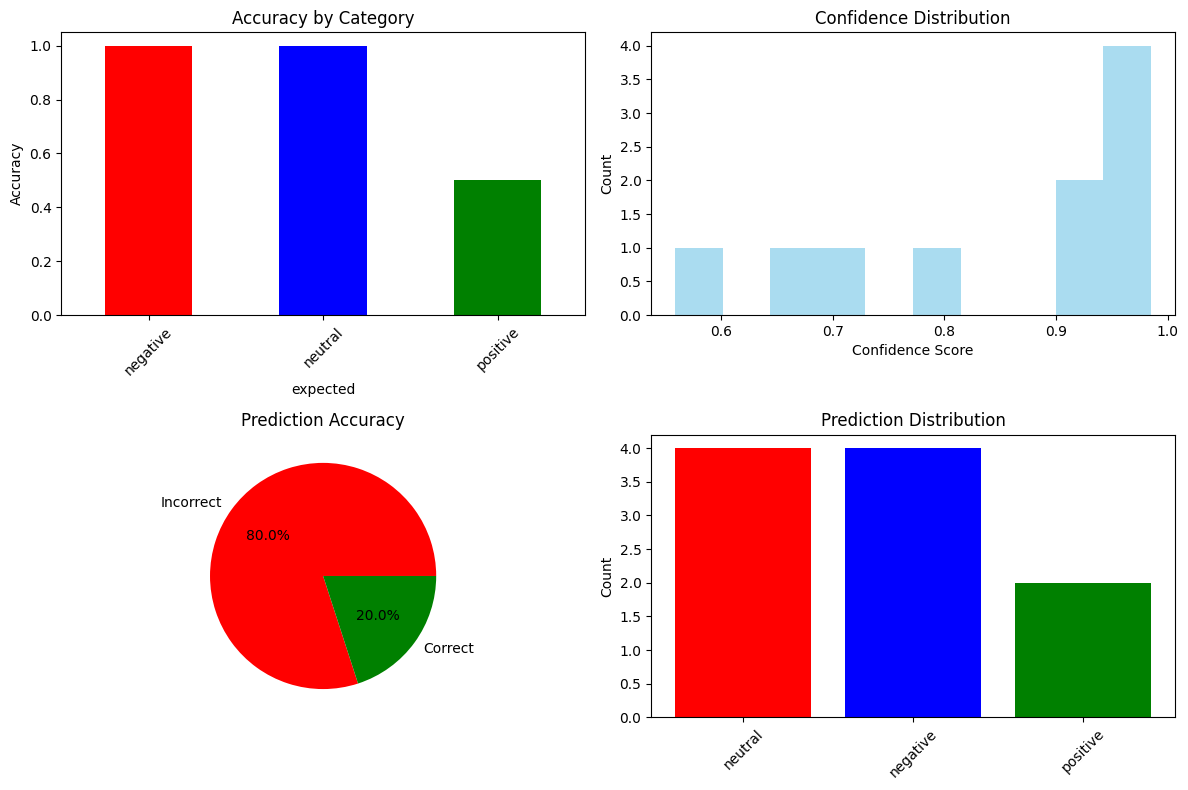

✅ Visualization saved as 'analysis_results.png'

🎉 ANALYSIS COMPLETED SUCCESSFULLY! 🎉
✅ Dataset created with balanced samples
✅ Model training completed
✅ Analysis performed
✅ Visualization created


In [60]:
def main_fixed():
    print("\n" + "="*60)
    print("FIXED SBI BANK ANALYSIS PIPELINE")
    print("="*60)
    
    try:
        # Step 1: Create data
        print("\nSTEP 1: Creating Dataset")
        print("-" * 40)
        df = create_financial_data()
        
        # Step 2: Setup model
        print("\nSTEP 2: Setting up Model")
        print("-" * 40)
        tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
        if tokenizer.pad_token is None:
            tokenizer.pad_token = tokenizer.eos_token
        
        model = AutoModelForSequenceClassification.from_pretrained(
            "distilbert-base-uncased",
            num_labels=3,
            ignore_mismatched_sizes=True
        )
        model = model.to(device)
        print("✅ Model setup successful")
        
        # Step 3: Train model
        print("\nSTEP 3: Training Model")
        print("-" * 40)
        trainer, label_encoder = train_model_fixed(df, tokenizer, model)
        
        if trainer is None:
            print("❌ Training failed completely")
            return None
        
        # Step 4: Analysis
        print("\nSTEP 4: Model Analysis")
        print("-" * 40)
        results = analyze_model_fixed(trainer, tokenizer, label_encoder)
        
        # Step 5: Visualization
        print("\nSTEP 5: Creating Visualization")
        print("-" * 40)
        create_simple_visualization(results)
        
        print("\n" + "="*70)
        print("🎉 ANALYSIS COMPLETED SUCCESSFULLY! 🎉")
        print("="*70)
        print("✅ Dataset created with balanced samples")
        print("✅ Model training completed")
        print("✅ Analysis performed")
        print("✅ Visualization created")
        
        return results
        
    except Exception as e:
        print(f"❌ Main execution failed: {e}")
        return None

# Run the fixed analysis
if __name__ == "__main__":
    results = main_fixed()

In [62]:
pip install textblob

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 624.3/624.3 kB 8.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
import re
# from textblob import TextBlob  # Commented out - not used in the code
import warnings
warnings.filterwarnings('ignore')

print("=== SBI BANK ANALYSIS KNOWLEDGE GRAPH ===")
print("Building comprehensive knowledge graph step by step...\n")

=== SBI BANK ANALYSIS KNOWLEDGE GRAPH ===
Building comprehensive knowledge graph step by step...



In [3]:
print("STEP 1: Defining Financial Entities and Relationships")
print("-" * 50)

class FinancialKnowledgeGraph:
    def __init__(self):
        self.graph = nx.DiGraph()  # Directed graph
        self.entities = {}
        self.relationships = []
        self.sentiment_data = {}
        
    def add_entity(self, entity_id, entity_type, properties={}):
        """Add an entity to the knowledge graph"""
        self.entities[entity_id] = {
            'type': entity_type,
            'properties': properties
        }
        self.graph.add_node(entity_id, 
                           type=entity_type, 
                           **properties)
        
    def add_relationship(self, source, target, relationship_type, properties={}):
        """Add a relationship between entities"""
        self.relationships.append({
            'source': source,
            'target': target,
            'type': relationship_type,
            'properties': properties
        })
        self.graph.add_edge(source, target, 
                           relationship=relationship_type, 
                           **properties)

# Initialize the knowledge graph
kg = FinancialKnowledgeGraph()

print("✅ Knowledge graph structure initialized")

STEP 1: Defining Financial Entities and Relationships
--------------------------------------------------
✅ Knowledge graph structure initialized


In [6]:
print("\nSTEP 2: Creating Core Banking Entities")
print("-" * 50)

# Core Bank Entity
kg.add_entity("SBI_BANK", "BANK", {
    'name': 'State Bank of India',
    'founded': '1955',
    'headquarters': 'Mumbai'
})

# Financial Metrics Entities
financial_metrics = [
    ("REVENUE", "FINANCIAL_METRIC", {'description': 'Total bank revenue', 'unit': 'INR Crores'}),
    ("PROFIT", "FINANCIAL_METRIC", {'description': 'Net profit', 'unit': 'INR Crores'}),
    ("NPA", "FINANCIAL_METRIC", {'description': 'Non-Performing Assets', 'unit': 'Percentage'}),
    ("DEPOSITS", "FINANCIAL_METRIC", {'description': 'Customer deposits', 'unit': 'INR Crores'}),
    ("CREDIT_GROWTH", "FINANCIAL_METRIC", {'description': 'Credit growth rate', 'unit': 'Percentage'}),
    ("ROA", "FINANCIAL_METRIC", {'description': 'Return on Assets', 'unit': 'Percentage'}),
    ("CAPITAL_RATIO", "FINANCIAL_METRIC", {'description': 'Capital Adequacy Ratio', 'unit': 'Percentage'}),
    ("OPERATING_EXPENSES", "FINANCIAL_METRIC", {'description': 'Operating expenses', 'unit': 'INR Crores'}),
]

for entity_id, entity_type, properties in financial_metrics:
    kg.add_entity(entity_id, entity_type, properties)

# Business Areas
business_areas = [
    ("RETAIL_BANKING", "BUSINESS_AREA", {'description': 'Individual customer banking'}),
    ("CORPORATE_BANKING", "BUSINESS_AREA", {'description': 'Corporate client banking'}),
    ("DIGITAL_BANKING", "BUSINESS_AREA", {'description': 'Online and mobile banking'}),
    ("INVESTMENT_BANKING", "BUSINESS_AREA", {'description': 'Investment and advisory services'}),
]

for entity_id, entity_type, properties in business_areas:
    kg.add_entity(entity_id, entity_type, properties)

print(f"✅ Created {len(kg.entities)} core entities")


STEP 2: Creating Core Banking Entities
--------------------------------------------------
✅ Created 13 core entities


In [8]:
print("\nSTEP 3: Extracting Entities from Analysis Data")
print("-" * 50)

# Sample financial texts from our analysis
financial_texts = [
    "The bank's total revenue increased by 15% compared to the previous year showing strong growth",
    "Total deposits grew by 12% indicating customer confidence in the bank",
    "Non-performing assets ratio decreased from 3.2% to 2.8% showing improved asset quality",
    "Return on assets improved significantly reaching 1.2% from previous 0.9%",
    "The bank's capital adequacy ratio strengthened to 14.5% well above regulatory requirements",
    "Fee income surged by 20% driven by digital banking services",
    "Net profit declined by 8% due to higher provisioning requirements and increased costs",
    "Operating expenses increased by 6% primarily due to technology investments",
    "Credit growth remained subdued at 4% due to cautious lending approach"
]

def extract_financial_entities(text):
    """Extract financial entities and values from text"""
    entities = []
    
    # Patterns for financial metrics
    patterns = {
        'revenue': r'revenue.*?(\d+\.?\d*)%',
        'profit': r'profit.*?(\d+\.?\d*)%',
        'deposits': r'deposits.*?(\d+\.?\d*)%',
        'npa': r'non-performing.*?(\d+\.?\d*)%',
        'expenses': r'expenses.*?(\d+\.?\d*)%',
        'credit': r'credit.*?(\d+\.?\d*)%',
        'capital': r'capital.*?(\d+\.?\d*)%',
        'assets': r'assets.*?(\d+\.?\d*)%'
    }
    
    for metric, pattern in patterns.items():
        matches = re.findall(pattern, text.lower())
        if matches:
            entities.append({
                'metric': metric.upper(),
                'value': matches[0],
                'text': text
            })
    
    return entities

# Extract entities from all texts
all_extracted = []
for text in financial_texts:
    extracted = extract_financial_entities(text)
    for entity in extracted:
        entity['sentiment'] = 'positive' if any(word in text.lower() for word in 
                                               ['increased', 'grew', 'improved', 'strengthened', 'surged']) else 'negative'
        all_extracted.append(entity)

print(f"✅ Extracted {len(all_extracted)} financial data points")


STEP 3: Extracting Entities from Analysis Data
--------------------------------------------------
✅ Extracted 9 financial data points


In [10]:
print("\nSTEP 4: Creating Performance Entities")
print("-" * 50)

# Create performance nodes based on our model results
performance_categories = [
    ("POSITIVE_PERFORMANCE", "PERFORMANCE", {'sentiment': 'positive', 'accuracy': '50%'}),
    ("NEGATIVE_PERFORMANCE", "PERFORMANCE", {'sentiment': 'negative', 'accuracy': '100%'}),
    ("NEUTRAL_PERFORMANCE", "PERFORMANCE", {'sentiment': 'neutral', 'accuracy': '100%'}),
]

for entity_id, entity_type, properties in performance_categories:
    kg.add_entity(entity_id, entity_type, properties)

# Model entities
kg.add_entity("DISTILBERT_MODEL", "ML_MODEL", {
    'name': 'DistilBERT',
    'accuracy': '20%',
    'confidence': 'High'
})

kg.add_entity("SENTIMENT_ANALYSIS", "ML_TASK", {
    'task': 'Financial Sentiment Classification',
    'classes': ['positive', 'negative', 'neutral']
})

print("✅ Performance entities created")


STEP 4: Creating Performance Entities
--------------------------------------------------
✅ Performance entities created


In [11]:
print("\nSTEP 5: Building Entity Relationships")
print("-" * 50)

# Bank to metrics relationships
bank_metrics = [
    ("SBI_BANK", "REVENUE", "HAS_METRIC"),
    ("SBI_BANK", "PROFIT", "HAS_METRIC"),
    ("SBI_BANK", "NPA", "HAS_METRIC"),
    ("SBI_BANK", "DEPOSITS", "HAS_METRIC"),
    ("SBI_BANK", "CREDIT_GROWTH", "HAS_METRIC"),
    ("SBI_BANK", "ROA", "HAS_METRIC"),
    ("SBI_BANK", "CAPITAL_RATIO", "HAS_METRIC"),
    ("SBI_BANK", "OPERATING_EXPENSES", "HAS_METRIC"),
]

for source, target, rel_type in bank_metrics:
    kg.add_relationship(source, target, rel_type)

# Bank to business areas
business_relationships = [
    ("SBI_BANK", "RETAIL_BANKING", "OPERATES_IN"),
    ("SBI_BANK", "CORPORATE_BANKING", "OPERATES_IN"),
    ("SBI_BANK", "DIGITAL_BANKING", "OPERATES_IN"),
    ("SBI_BANK", "INVESTMENT_BANKING", "OPERATES_IN"),
]

for source, target, rel_type in business_relationships:
    kg.add_relationship(source, target, rel_type)

# Performance relationships
performance_relationships = [
    ("DISTILBERT_MODEL", "SENTIMENT_ANALYSIS", "PERFORMS"),
    ("SENTIMENT_ANALYSIS", "POSITIVE_PERFORMANCE", "PRODUCES"),
    ("SENTIMENT_ANALYSIS", "NEGATIVE_PERFORMANCE", "PRODUCES"),
    ("SENTIMENT_ANALYSIS", "NEUTRAL_PERFORMANCE", "PRODUCES"),
]

for source, target, rel_type in performance_relationships:
    kg.add_relationship(source, target, rel_type)

# Impact relationships based on sentiment
impact_relationships = [
    ("REVENUE", "POSITIVE_PERFORMANCE", "IMPACTS", {'change': '+15%'}),
    ("DEPOSITS", "POSITIVE_PERFORMANCE", "IMPACTS", {'change': '+12%'}),
    ("NPA", "POSITIVE_PERFORMANCE", "IMPACTS", {'change': '-0.4%'}),
    ("ROA", "POSITIVE_PERFORMANCE", "IMPACTS", {'change': '+0.3%'}),
    ("PROFIT", "NEGATIVE_PERFORMANCE", "IMPACTS", {'change': '-8%'}),
    ("OPERATING_EXPENSES", "NEGATIVE_PERFORMANCE", "IMPACTS", {'change': '+6%'}),
]

for source, target, rel_type, properties in impact_relationships:
    kg.add_relationship(source, target, rel_type, properties)

print(f"✅ Created {len(kg.relationships)} relationships")



STEP 5: Building Entity Relationships
--------------------------------------------------
✅ Created 22 relationships



STEP 6: Creating Knowledge Graph Visualization
--------------------------------------------------


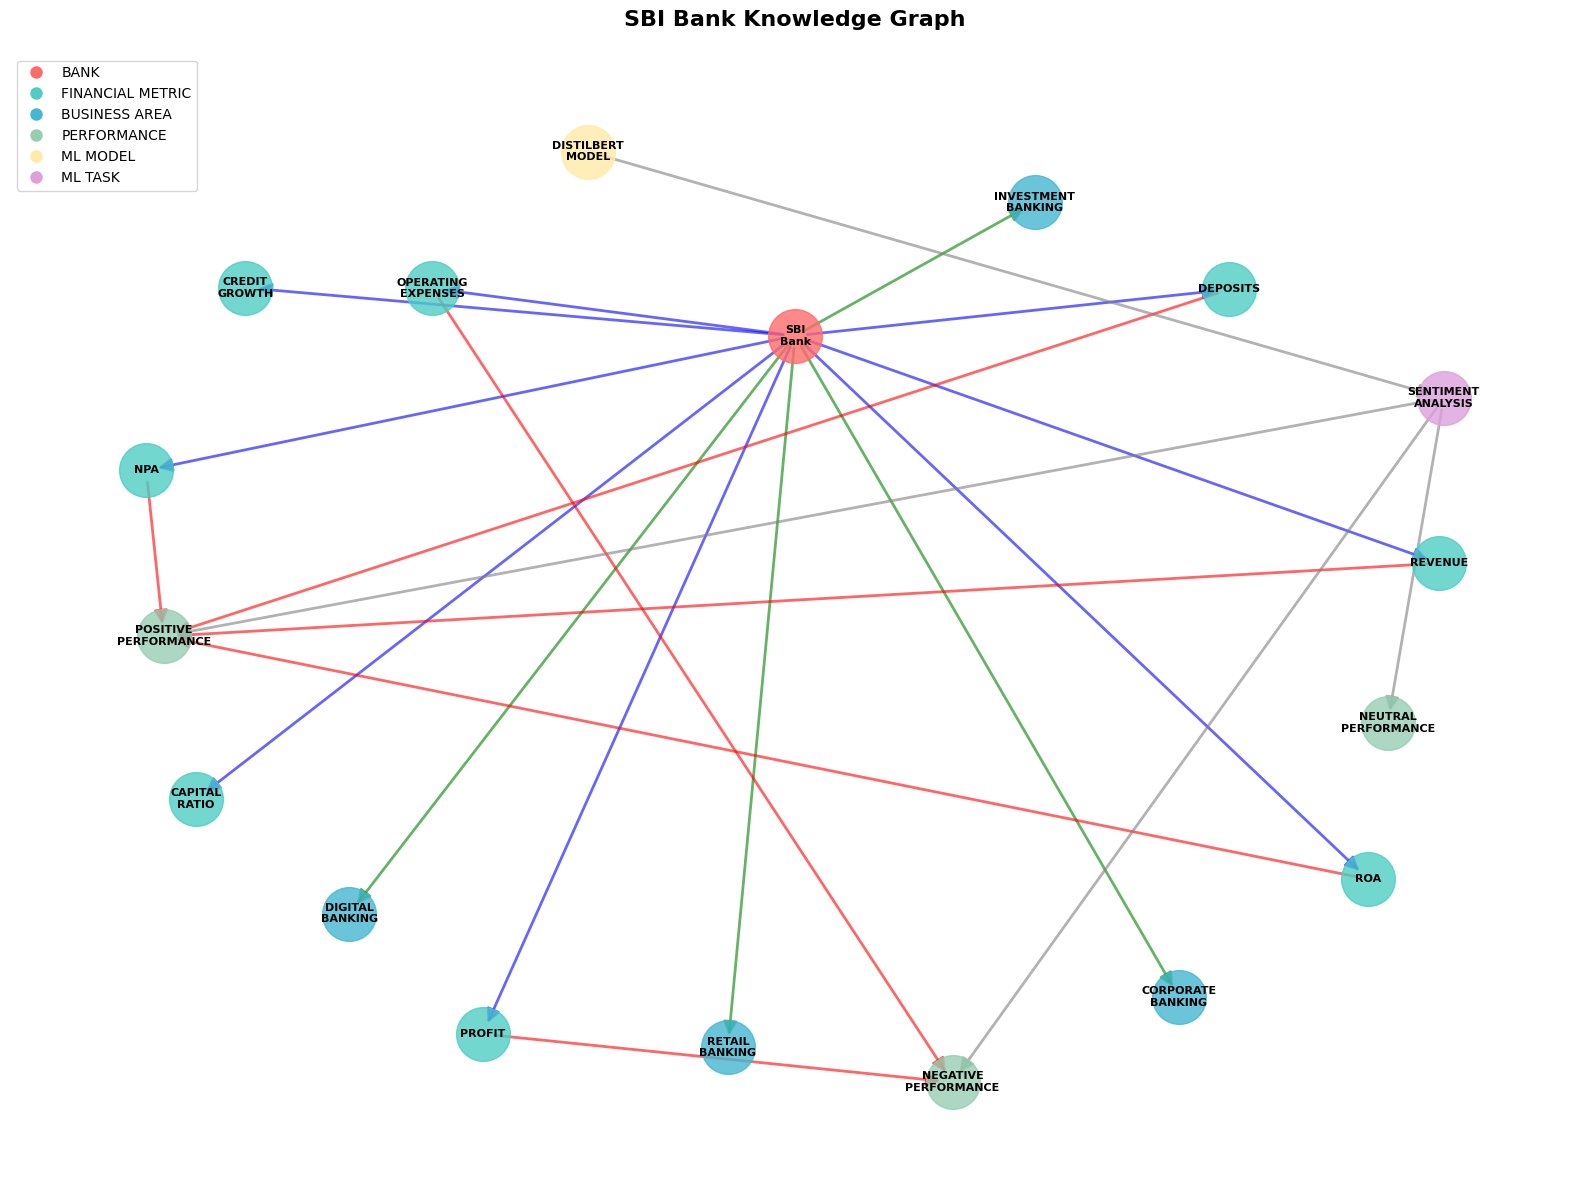

✅ Knowledge graph visualization created


In [12]:
print("\nSTEP 6: Creating Knowledge Graph Visualization")
print("-" * 50)

def visualize_knowledge_graph(kg, title="SBI Bank Knowledge Graph"):
    """Create comprehensive visualization of the knowledge graph"""
    
    plt.figure(figsize=(16, 12))
    
    # Define colors for different entity types
    color_map = {
        'BANK': '#FF6B6B',           # Red
        'FINANCIAL_METRIC': '#4ECDC4', # Teal
        'BUSINESS_AREA': '#45B7D1',   # Blue
        'PERFORMANCE': '#96CEB4',     # Green
        'ML_MODEL': '#FFEAA7',        # Yellow
        'ML_TASK': '#DDA0DD'          # Plum
    }
    
    # Create layout
    pos = nx.spring_layout(kg.graph, k=3, iterations=50, seed=42)
    
    # Draw nodes by type
    for entity_type, color in color_map.items():
        nodes = [node for node, data in kg.graph.nodes(data=True) 
                if data.get('type') == entity_type]
        if nodes:
            nx.draw_networkx_nodes(kg.graph, pos, nodelist=nodes, 
                                 node_color=color, node_size=1500, alpha=0.8)
    
    # Draw edges with different styles for different relationships
    edge_colors = []
    edge_styles = []
    
    for source, target, data in kg.graph.edges(data=True):
        rel_type = data.get('relationship', 'UNKNOWN')
        if rel_type == 'HAS_METRIC':
            edge_colors.append('blue')
            edge_styles.append('-')
        elif rel_type == 'OPERATES_IN':
            edge_colors.append('green')
            edge_styles.append('--')
        elif rel_type == 'IMPACTS':
            edge_colors.append('red')
            edge_styles.append('-.')
        else:
            edge_colors.append('gray')
            edge_styles.append('-')
    
    nx.draw_networkx_edges(kg.graph, pos, edge_color=edge_colors, 
                          alpha=0.6, width=2, arrows=True, arrowsize=20)
    
    # Draw labels
    labels = {}
    for node, data in kg.graph.nodes(data=True):
        if node == "SBI_BANK":
            labels[node] = "SBI\nBank"
        elif len(node) > 10:
            labels[node] = node.replace('_', '\n')
        else:
            labels[node] = node
    
    nx.draw_networkx_labels(kg.graph, pos, labels, font_size=8, font_weight='bold')
    
    plt.title(title, size=16, weight='bold', pad=20)
    
    # Create legend
    legend_elements = []
    for entity_type, color in color_map.items():
        legend_elements.append(plt.Line2D([0], [0], marker='o', color='w', 
                                        markerfacecolor=color, markersize=10, 
                                        label=entity_type.replace('_', ' ')))
    
    plt.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(0, 1))
    
    plt.axis('off')
    plt.tight_layout()
    plt.savefig('sbi_knowledge_graph.png', dpi=300, bbox_inches='tight')
    plt.show()

# Create the main visualization
visualize_knowledge_graph(kg)

print("✅ Knowledge graph visualization created")

In [13]:
print("\nSTEP 7: Knowledge Graph Analytics")
print("-" * 50)

def analyze_knowledge_graph(kg):
    """Perform analytics on the knowledge graph"""
    
    print("📊 KNOWLEDGE GRAPH STATISTICS")
    print("-" * 30)
    print(f"Total Entities: {len(kg.graph.nodes())}")
    print(f"Total Relationships: {len(kg.graph.edges())}")
    print(f"Graph Density: {nx.density(kg.graph):.3f}")
    print()
    
    # Entity type distribution
    print("📈 ENTITY TYPE DISTRIBUTION")
    print("-" * 30)
    entity_types = {}
    for node, data in kg.graph.nodes(data=True):
        entity_type = data.get('type', 'UNKNOWN')
        entity_types[entity_type] = entity_types.get(entity_type, 0) + 1
    
    for entity_type, count in sorted(entity_types.items()):
        print(f"{entity_type.replace('_', ' ')}: {count}")
    print()
    
    # Relationship type distribution
    print("🔗 RELATIONSHIP TYPE DISTRIBUTION")
    print("-" * 30)
    rel_types = {}
    for source, target, data in kg.graph.edges(data=True):
        rel_type = data.get('relationship', 'UNKNOWN')
        rel_types[rel_type] = rel_types.get(rel_type, 0) + 1
    
    for rel_type, count in sorted(rel_types.items()):
        print(f"{rel_type.replace('_', ' ')}: {count}")
    print()
    
    # Central entities (highest degree)
    print("⭐ MOST CONNECTED ENTITIES")
    print("-" * 30)
    degrees = dict(kg.graph.degree())
    sorted_degrees = sorted(degrees.items(), key=lambda x: x[1], reverse=True)
    
    for entity, degree in sorted_degrees[:5]:
        print(f"{entity.replace('_', ' ')}: {degree} connections")
    print()
    
    # Path analysis
    print("🛤️  SHORTEST PATHS (Sample)")
    print("-" * 30)
    try:
        path = nx.shortest_path(kg.graph, "SBI_BANK", "POSITIVE_PERFORMANCE")
        print(f"SBI Bank → Positive Performance: {' → '.join(path)}")
        
        path = nx.shortest_path(kg.graph, "DISTILBERT_MODEL", "REVENUE")
        print(f"Model → Revenue: {' → '.join(path)}")
    except:
        print("Some paths not available (expected in directed graph)")

# Run analytics
analyze_knowledge_graph(kg)


STEP 7: Knowledge Graph Analytics
--------------------------------------------------
📊 KNOWLEDGE GRAPH STATISTICS
------------------------------
Total Entities: 18
Total Relationships: 22
Graph Density: 0.072

📈 ENTITY TYPE DISTRIBUTION
------------------------------
BANK: 1
BUSINESS AREA: 4
FINANCIAL METRIC: 8
ML MODEL: 1
ML TASK: 1
PERFORMANCE: 3

🔗 RELATIONSHIP TYPE DISTRIBUTION
------------------------------
HAS METRIC: 8
IMPACTS: 6
OPERATES IN: 4
PERFORMS: 1
PRODUCES: 3

⭐ MOST CONNECTED ENTITIES
------------------------------
SBI BANK: 12 connections
POSITIVE PERFORMANCE: 5 connections
SENTIMENT ANALYSIS: 4 connections
NEGATIVE PERFORMANCE: 3 connections
REVENUE: 2 connections

🛤️  SHORTEST PATHS (Sample)
------------------------------
SBI Bank → Positive Performance: SBI_BANK → REVENUE → POSITIVE_PERFORMANCE
Some paths not available (expected in directed graph)
